# Freight rate assessment — Stage 3: Features and LightGBM

Run the cells from top to bottom. This notebook reuses the Stage 3 implementation in `stage3_modeling.py` and saves metrics, diagnostics, and December forecasts under `outputs/stage3/`.

Select the project environment (`.\\env\\Scripts\\python.exe`) as the VS Code notebook kernel. If packages are missing, install them in PowerShell from the project directory:

```powershell
.\env\Scripts\python.exe -m pip install -r requirements.txt
```

The September–October holdout is not used for tuning. Lane target encodings for training rows use only earlier dates; each evaluation fold receives encodings from its training partition. Variant A omits market signals. Variant B forecasts both signals from the latest eight weekly training averages and clips extrapolations to the training 1st–99th percentile range.

## 1. Load workflow and training data

In [1]:
from pathlib import Path
import runpy

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

stage3 = runpy.run_path(str(Path.cwd() / "stage3_modeling.py"))
data = stage3["load_training_data"]()
OUTPUT_DIR = stage3["OUTPUT_DIR"]
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Shape:", data.shape)
print("Date range:", data["date"].min().date(), "to", data["date"].max().date())
print("Missing weight:", data["weight"].isna().sum())
print("Negative weights converted to absolute values before modeling.")

c:\Users\redni\Downloads\ML-Assessment\env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Shape: (48000, 14)
Date range: 2025-01-01 to 2025-10-31
Missing weight: 300
Negative weights converted to absolute values before modeling.


## 2. Tune LightGBM using expanding-window CV

Six Optuna trials optimize mean MAE over May–August folds for the signal-free variant. The same chosen hyperparameters are used for both variants to keep their holdout comparison controlled.

In [2]:
best_parameters, trials = stage3["tune_lightgbm"](data)
trials.to_csv(OUTPUT_DIR / "optuna_trials.csv", index=False)
print("Best parameters:")
display(pd.Series(best_parameters, name="value").to_frame())
print("Optuna trial scores (MAE objective):")
display(trials.sort_values("value").head(6))

Best parameters:


,value
n_estimators,500
learning_rate,0.056097
num_leaves,8
max_depth,5
min_child_samples,96
reg_lambda,0.300223
include_signals,False


Optuna trial scores (MAE objective):


,number,value,datetime_start,datetime_complete,duration,params_learning_rate,params_max_depth,params_min_child_samples,params_n_estimators,params_num_leaves,params_reg_lambda,state
1,1,134.048301,2026-11-02 18:29:58.939880,2026-11-02 18:30:05.353309,0 days 00:00:06.413429,0.056097,5,96,500,8,0.300223,COMPLETE
5,5,135.093408,2026-11-02 18:30:24.266777,2026-11-02 18:30:29.877716,0 days 00:00:05.610939,0.088707,3,64,200,30,0.794794,COMPLETE
2,2,135.440732,2026-11-02 18:30:05.353309,2026-11-02 18:30:11.730092,0 days 00:00:06.376783,0.096315,8,64,600,9,2.987566,COMPLETE
0,0,135.613192,2026-11-02 18:29:53.036954,2026-11-02 18:29:58.939880,0 days 00:00:05.902926,0.051750,3,83,300,14,3.281668,COMPLETE
3,3,136.644193,2026-11-02 18:30:11.730092,2026-11-02 18:30:18.376361,0 days 00:00:06.646269,0.033208,7,52,400,19,3.943504,COMPLETE
4,4,138.264593,2026-11-02 18:30:18.377364,2026-11-02 18:30:24.266777,0 days 00:00:05.889413,0.025883,3,78,400,13,1.461587,COMPLETE


## 3. CV comparison against Stage 2 baselines

In [3]:
cv_metrics, _ = stage3["evaluate_cv"](data, best_parameters)
cv_metrics.to_csv(OUTPUT_DIR / "cv_metrics.csv", index=False)
display(cv_metrics.sort_values(["split", "model"]).round(4))
print("Mean CV metrics:")
display(
    cv_metrics.groupby("model")[["MAE", "RMSE", "MAPE_pct", "RMSLE"]]
    .mean()
    .sort_values("MAE")
    .round(4)
)

,split,model,MAE,RMSE,MAPE_pct,RMSLE
1,cv_2025_05,lightgbm_A_no_signals,118.5799,562.9934,5.8413,0.1593
2,cv_2025_05,lightgbm_B_estimated_signals,137.8051,570.9141,6.2604,0.1606
0,cv_2025_05,median_rate_per_mile,224.2299,605.0955,11.5414,0.2002
12,cv_2025_05,stage2_ridge_log_target,131.9399,566.9741,6.0003,0.1593
4,cv_2025_06,lightgbm_A_no_signals,155.9820,717.1422,5.4407,0.1539
5,cv_2025_06,lightgbm_B_estimated_signals,145.4098,712.7553,5.3171,0.1539
3,cv_2025_06,median_rate_per_mile,257.3009,732.6369,11.9582,0.2054
13,cv_2025_06,stage2_ridge_log_target,148.6917,715.7491,5.0138,0.1525
7,cv_2025_07,lightgbm_A_no_signals,162.2152,631.4195,7.1026,0.1560
8,cv_2025_07,lightgbm_B_estimated_signals,179.6179,633.6319,7.9960,0.1596


Mean CV metrics:


,MAE,RMSE,MAPE_pct,RMSLE
model,,,,
stage2_ridge_log_target,133.7565,631.6701,5.5736,0.1551
lightgbm_A_no_signals,134.0483,631.9879,5.7642,0.1562
lightgbm_B_estimated_signals,142.9080,633.8302,6.1728,0.1577
median_rate_per_mile,245.9254,672.4659,11.4744,0.1962


## 4. Untouched September–October holdout

Variant B estimates its signal features using only data before September 1. The error tables break down holdout performance by equipment, distance bucket, and month.

In [4]:
holdout_metrics, holdout_predictions, holdout_models = stage3["evaluate_holdout"](
    data, best_parameters
)
holdout_metrics.to_csv(OUTPUT_DIR / "holdout_metrics.csv", index=False)
holdout_predictions.to_csv(OUTPUT_DIR / "holdout_predictions.csv", index=False)
error_breakdown = stage3["make_error_breakdown"](holdout_predictions)
error_breakdown.to_csv(OUTPUT_DIR / "holdout_error_breakdown.csv", index=False)

print("Holdout comparison:")
display(holdout_metrics[["model", "MAE", "RMSE", "MAPE_pct", "RMSLE"]].round(4))
print("Error breakdown:")
display(error_breakdown.round(3))

Holdout comparison:


,model,MAE,RMSE,MAPE_pct,RMSLE
0,median_rate_per_mile,256.9529,684.2479,11.6315,0.1981
1,lightgbm_A_no_signals,126.9891,639.9398,5.4325,0.1621
2,lightgbm_B_estimated_signals,141.6588,644.0144,6.1103,0.1643
3,stage2_ridge_log_target,161.8469,651.8776,6.6795,0.1656


Error breakdown:


,model,breakdown,group,n,MAE,RMSE,MAPE_pct,RMSLE
0,median_rate_per_mile,equipment,Dry Van,5360,288.549,721.979,11.497,0.195
1,median_rate_per_mile,equipment,Flatbed,1770,198.490,537.913,11.022,0.186
2,median_rate_per_mile,equipment,Reefer,2393,229.424,694.000,12.383,0.213
3,median_rate_per_mile,distance_bucket,1000-1500,1760,223.215,702.832,8.586,0.174
4,median_rate_per_mile,distance_bucket,1500-2000,1167,360.505,1024.691,10.105,0.186
5,median_rate_per_mile,distance_bucket,500-1000,2972,141.982,387.127,8.922,0.173
6,median_rate_per_mile,distance_bucket,<=500,2090,138.328,276.159,17.466,0.257
7,median_rate_per_mile,distance_bucket,>2000,1534,601.251,1070.857,13.587,0.188
8,median_rate_per_mile,month,2025-09,4670,260.832,673.303,11.448,0.190
9,median_rate_per_mile,month,2025-10,4853,253.220,694.617,11.808,0.206


## 5. Feature importance

Importances are calculated from each model trained on the pre-holdout period. One-hot encoded categorical features are shown separately.

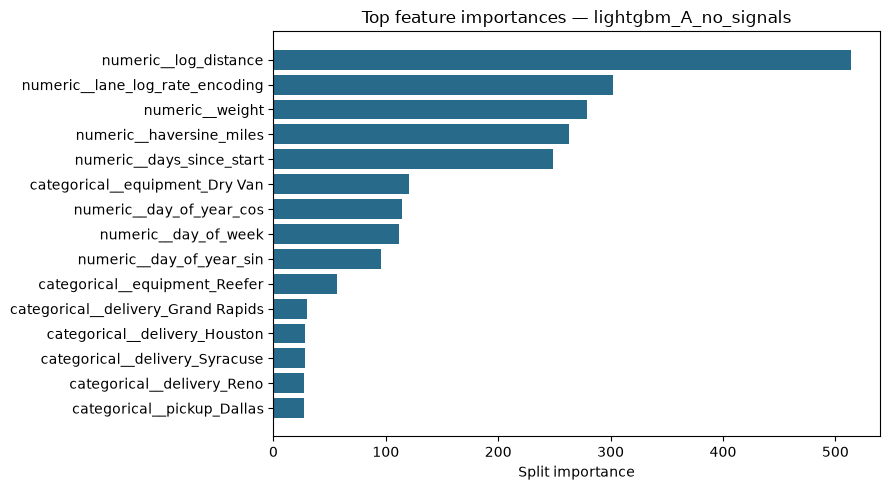

,model,feature,importance,importance_share
0,lightgbm_A_no_signals,numeric__log_distance,514,0.1469
1,lightgbm_A_no_signals,numeric__lane_log_rate_encoding,302,0.0863
2,lightgbm_A_no_signals,numeric__weight,279,0.0797
3,lightgbm_A_no_signals,numeric__haversine_miles,263,0.0751
4,lightgbm_A_no_signals,numeric__days_since_start,249,0.0711
5,lightgbm_A_no_signals,categorical__equipment_Dry Van,121,0.0346
6,lightgbm_A_no_signals,numeric__day_of_year_cos,114,0.0326
7,lightgbm_A_no_signals,numeric__day_of_week,112,0.0320
8,lightgbm_A_no_signals,numeric__day_of_year_sin,96,0.0274
9,lightgbm_A_no_signals,categorical__equipment_Reefer,57,0.0163


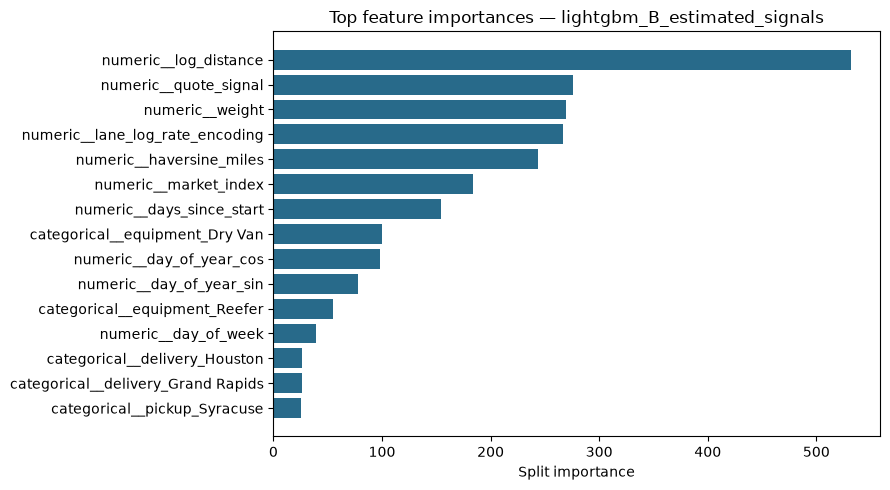

,model,feature,importance,importance_share
145,lightgbm_B_estimated_signals,numeric__log_distance,532,0.1520
146,lightgbm_B_estimated_signals,numeric__quote_signal,276,0.0789
147,lightgbm_B_estimated_signals,numeric__weight,269,0.0769
148,lightgbm_B_estimated_signals,numeric__lane_log_rate_encoding,267,0.0763
149,lightgbm_B_estimated_signals,numeric__haversine_miles,244,0.0697
150,lightgbm_B_estimated_signals,numeric__market_index,184,0.0526
151,lightgbm_B_estimated_signals,numeric__days_since_start,154,0.0440
152,lightgbm_B_estimated_signals,categorical__equipment_Dry Van,100,0.0286
153,lightgbm_B_estimated_signals,numeric__day_of_year_cos,98,0.0280
154,lightgbm_B_estimated_signals,numeric__day_of_year_sin,78,0.0223


In [5]:
fit = data.loc[data["date"] < stage3["HOLDOUT_START"]]
evaluation = data.loc[data["date"] >= stage3["HOLDOUT_START"]]
importance_frames = []
for model_name, model in holdout_models.items():
    include_signals = model_name.endswith("estimated_signals")
    x_fit, _, _, _ = stage3["build_feature_matrices"](
        fit, evaluation, include_signals
    )
    importance_frames.append(
        stage3["extract_importance"](model, x_fit.columns.tolist(), model_name)
    )
feature_importance = pd.concat(importance_frames, ignore_index=True)
feature_importance.to_csv(OUTPUT_DIR / "feature_importance.csv", index=False)

for model_name, frame in feature_importance.groupby("model"):
    top_features = frame.head(15).sort_values("importance")
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.barh(top_features["feature"], top_features["importance"], color="#286a8a")
    ax.set(title=f"Top feature importances — {model_name}", xlabel="Split importance")
    fig.tight_layout()
    plt.show()
    plt.close(fig)
    display(frame.head(15).round(4))

## 6. December predictions and estimated market signals

The December file lacks coordinates and market signals. Coordinates are recovered from the consistent city mappings in the labeled training data. Variant B extrapolates each signal from the latest eight weekly averages; Variant A does not require either signal.

In [6]:
december_predictions, december_signal_forecasts = stage3[
    "generate_december_predictions"
](data, best_parameters)
december_predictions.to_csv(OUTPUT_DIR / "december_predictions.csv", index=False)
december_signal_forecasts.to_csv(
    OUTPUT_DIR / "december_estimated_signals.csv", index=False
)
display(december_predictions.round(2))

c:\Users\redni\Downloads\ML-Assessment\stage3_modeling.py:107: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[]' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  result.loc[missing_coords, lat_col] = city_coords[missing_coords].map(
c:\Users\redni\Downloads\ML-Assessment\stage3_modeling.py:110: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[]' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  result.loc[missing_coords, lon_col] = city_coords[missing_coords].map(
c:\Users\redni\Downloads\ML-Assessment\stage3_modeling.py:107: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[]' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.

,pickup,delivery,distance,equipment,weight,date,estimated_market_index,estimated_quote_signal,predicted_rate_lightgbm_A_no_signals,predicted_rate_lightgbm_B_estimated_signals
0,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-01,1.02,1.69,826.37,830.53
1,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-02,1.02,1.68,831.60,831.17
2,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-03,1.02,1.68,841.72,832.34
3,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-04,1.02,1.67,839.81,830.38
4,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-05,1.03,1.66,834.65,828.22
5,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-06,1.03,1.66,826.14,828.22
6,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-07,1.03,1.65,821.17,828.22
7,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-08,1.03,1.64,824.51,828.90
8,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-09,1.03,1.64,829.71,829.84
9,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-10,1.03,1.63,839.81,831.07


## Recommendation notes

Choose the variant using the untouched holdout first, then check whether the CV pattern supports it. Variant A is preferred if extrapolated market signals fail to improve the holdout: December has no observed signal data, and signal forecasts add uncertainty. Treat feature importance as descriptive rather than causal.